# 03 — Logistic Regression

**Hướng dẫn cho thành viên phụ trách:**
- Chọn kernel `.venv` của dự án và chạy **Restart & Run All** từ đầu đến cuối.
- Toàn bộ dữ liệu, chia tập (80/20) và `preprocessor` được nạp thống nhất từ thư mục `src/` (`src/config.py`, `src/data.py`, `src/modeling.py`) để **không lặp code** và đảm bảo **0% data leakage**.
- **Quy tắc bắt buộc:** Các thí nghiệm E1–E6 bên dưới chỉ sử dụng **tập Train (40.837 dòng)** qua 5-fold Stratified CV. **Tuyệt đối không dùng tập Test** để chọn mô hình hay chỉnh tham số.
- Kết quả tóm tắt sẽ tự động lưu tại `results/metrics/03_logistic_regression.json` để notebook `07_comparison.ipynb` tổng hợp.

## 1. Nạp dữ liệu từ `src/` & Cấu hình mô hình
Thành viên có thể mở rộng thêm siêu tham số trong `PARAM_SPACE` nếu muốn khảo sát sâu hơn.

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import SelectPercentile, f_classif
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import RANDOM_STATE, SCORING, make_cv
from src.data import load_train_test
from src.modeling import (
    build_preprocessor,
    make_pipeline,
    evaluate_cv,
    scan_oof_thresholds,
    save_cv_report,
)

X_train, X_test, y_train, y_test, NUM_COLS, CAT_COLS = load_train_test()
preprocessor = build_preprocessor(NUM_COLS, CAT_COLS, min_frequency=50)
cv = make_cv()

MODEL_NAME = "Logistic Regression"
REPORT_FILE = "03_logistic_regression.json"
BASE_MODEL = LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)
PARAM_SPACE = {
    "model__C": [0.001, 0.01, 0.1, 1.0, 10.0],
    "model__class_weight": [None, "balanced"],
}

print(f"Ready | {MODEL_NAME} | Train={X_train.shape} | Test={X_test.shape} | Churn={y_train.mean():.4f}")

Ready | Logistic Regression | Train=(40837, 53) | Test=(10210, 53) | Churn=0.2882


## 2. E1 — Baseline 5-fold CV
Đánh giá mô hình mặc định trên 5 thước đo: `f1`, `recall`, `precision`, `roc_auc`, `ap` (PR-AUC).

In [2]:
t0 = time.time()
baseline_pipe = make_pipeline(preprocessor, BASE_MODEL)
base_cv, base_summary = evaluate_cv(baseline_pipe, X_train, y_train, cv)
print(f"E1 xong sau {time.time() - t0:.1f}s")
display(base_summary)

E1 xong sau 13.2s


,metric,mean,std
0,f1,0.0735,0.0077
1,recall,0.0398,0.0044
2,precision,0.4885,0.0193
3,roc_auc,0.6138,0.0063
4,ap,0.3774,0.0055


## 3. E2 — Hyperparameter Tuning (`GridSearchCV`)
Tối ưu F1 trên tập Train (bao gồm cả `class_weight` để so sánh công bằng). Kiểm tra chênh lệch `mean_train_score` và `mean_test_score` để phát hiện overfitting.

In [3]:
t0 = time.time()
search = GridSearchCV(
    estimator=clone(baseline_pipe),
    param_grid=PARAM_SPACE,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    refit=True,
)
search.fit(X_train, y_train)

best_model = clone(search.best_estimator_.named_steps["model"])
tuned_cv, tuned_summary = evaluate_cv(make_pipeline(preprocessor, best_model), X_train, y_train, cv)

print(f"E2 xong sau {time.time() - t0:.1f}s | Best CV F1: {search.best_score_:.4f}")
print("Best params:", search.best_params_)
display(
    pd.DataFrame(search.cv_results_)
    .sort_values("rank_test_score")[["params", "mean_train_score", "mean_test_score", "std_test_score"]]
    .head(8)
    .round(4)
)
display(tuned_summary)

E2 xong sau 52.6s | Best CV F1: 0.4483
Best params: {'model__C': 0.01, 'model__class_weight': 'balanced'}


,params,mean_train_score,mean_test_score,std_test_score
3,"{'model__C': 0.01, 'model__class_weight': 'bal...",0.4567,0.4483,0.0059
5,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.4594,0.4469,0.0059
1,"{'model__C': 0.001, 'model__class_weight': 'ba...",0.4486,0.4454,0.0036
7,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.4593,0.4446,0.0059
9,"{'model__C': 10.0, 'model__class_weight': 'bal...",0.4595,0.4444,0.0060
8,"{'model__C': 10.0, 'model__class_weight': None}",0.0827,0.0749,0.0080
6,"{'model__C': 1.0, 'model__class_weight': None}",0.0806,0.0735,0.0077
4,"{'model__C': 0.1, 'model__class_weight': None}",0.0710,0.0652,0.0064


,metric,mean,std
0,f1,0.4483,0.0059
1,recall,0.5842,0.0081
2,precision,0.3638,0.0056
3,roc_auc,0.6196,0.0071
4,ap,0.3800,0.0057


## 4. E3 — Xử lý mất cân bằng lớp
So sánh `baseline` với `class_weight="balanced"` và `SMOTE` (đặt bên trong `ImbPipeline` để chỉ oversample trên từng fold huấn luyện).

In [4]:
t0 = time.time()
weighted_pipe = make_pipeline(
    preprocessor,
    clone(BASE_MODEL).set_params(class_weight="balanced"),
)
weighted_cv, _ = evaluate_cv(weighted_pipe, X_train, y_train, cv)

smote_pipe = ImbPipeline([
    ("preprocessor", clone(preprocessor)),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", clone(BASE_MODEL)),
])
smote_cv, _ = evaluate_cv(smote_pipe, X_train, y_train, cv)

display(
    pd.DataFrame({
        "metric": list(SCORING),
        "baseline": [base_cv[f"test_{k}"].mean() for k in SCORING],
        "class_weight_balanced": [weighted_cv[f"test_{k}"].mean() for k in SCORING],
        "smote": [smote_cv[f"test_{k}"].mean() for k in SCORING],
    }).round(4)
)
print(f"E3 xong sau {time.time() - t0:.1f}s")

,metric,baseline,class_weight_balanced,smote
0,f1,0.0735,0.4446,0.4407
1,recall,0.0398,0.5768,0.5807
2,precision,0.4885,0.3618,0.3551
3,roc_auc,0.6138,0.6142,0.6077
4,ap,0.3774,0.3773,0.3715


E3 xong sau 39.9s


## 5. E4 — Feature Selection (`SelectPercentile`)
Thử giữ lại top 60% đặc trưng theo `f_classif` bên trong pipeline CV trên mô hình đã tune để đánh giá mức độ ảnh hưởng đến F1 và thời gian chạy.

In [5]:
t0 = time.time()
fs_pipe = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("selector", SelectPercentile(score_func=f_classif, percentile=60)),
    ("model", clone(best_model)),
])
fs_cv, _ = evaluate_cv(fs_pipe, X_train, y_train, cv)

display(
    pd.DataFrame({
        "metric": list(SCORING),
        "tuned_full": [tuned_cv[f"test_{k}"].mean() for k in SCORING],
        "tuned_top60pct": [fs_cv[f"test_{k}"].mean() for k in SCORING],
    }).round(4)
)
print(f"E4 xong sau {time.time() - t0:.1f}s")

,metric,tuned_full,tuned_top60pct
0,f1,0.4483,0.4476
1,recall,0.5842,0.5830
2,precision,0.3638,0.3633
3,roc_auc,0.6196,0.6191
4,ap,0.3800,0.3793


E4 xong sau 5.7s


## 6. E5 — Stability Analysis qua 5 fold
Kiểm tra độ ổn định của F1 và ROC-AUC giữa 5 fold.

,fold,baseline_f1,tuned_f1,tuned_roc_auc
0,1,0.0611,0.4540,0.6308
1,2,0.0710,0.4532,0.6182
2,3,0.0849,0.4520,0.6240
3,4,0.0747,0.4417,0.6141
4,5,0.0758,0.4407,0.6110


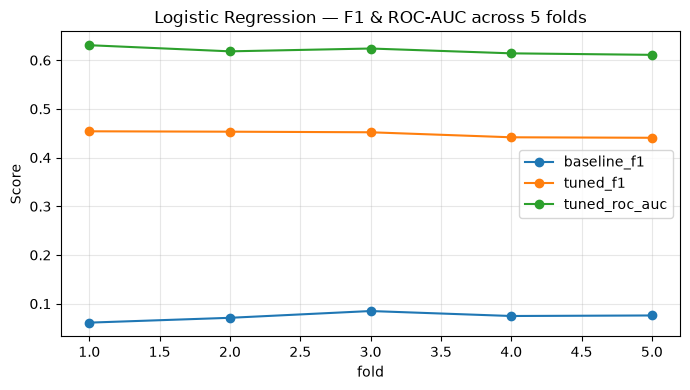

In [6]:
stability = pd.DataFrame({
    "fold": range(1, 6),
    "baseline_f1": base_cv["test_f1"],
    "tuned_f1": tuned_cv["test_f1"],
    "tuned_roc_auc": tuned_cv["test_roc_auc"],
}).round(4)
display(stability)

ax = stability.set_index("fold").plot(
    marker="o", figsize=(7, 4), title=f"{MODEL_NAME} — F1 & ROC-AUC across 5 folds"
)
ax.set_ylabel("Score")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. E6 — Threshold Analysis (OOF trên Train) & Lưu `03_logistic_regression.json`
Quét ngưỡng quyết định trên xác suất out-of-fold của tập Train (không chạm tập Test), sau đó xuất báo cáo JSON để notebook `07_comparison.ipynb` đọc tự động.

In [7]:
t0 = time.time()
thresh_df, best_threshold, best_oof_f1 = scan_oof_thresholds(
    preprocessor, best_model, X_train, y_train, cv
)
print(f"E6 xong sau {time.time() - t0:.1f}s | Best OOF threshold: {best_threshold} (F1={best_oof_f1:.4f})")
display(thresh_df)

def _py_val(v):
    if isinstance(v, np.integer):
        return int(v)
    if isinstance(v, np.floating):
        return float(v)
    return v

report = {
    "model": MODEL_NAME,
    "baseline_cv": {k: round(float(base_cv[f"test_{k}"].mean()), 4) for k in SCORING},
    "weighted_cv": {k: round(float(weighted_cv[f"test_{k}"].mean()), 4) for k in SCORING},
    "smote_cv": {k: round(float(smote_cv[f"test_{k}"].mean()), 4) for k in SCORING},
    "tuned_cv": {k: round(float(tuned_cv[f"test_{k}"].mean()), 4) for k in SCORING},
    "tuned_cv_f1_std": round(float(tuned_cv["test_f1"].std()), 4),
    "tuned_best_cv_f1": round(float(search.best_score_), 4),
    "tuned_best_params": {
        k.replace("model__", ""): _py_val(v)
        for k, v in search.best_params_.items()
    },
    "best_oof_threshold": best_threshold,
    "best_oof_f1_at_threshold": round(best_oof_f1, 4),
}

saved_path = save_cv_report(REPORT_FILE, report)
print("Đã lưu kết quả CV tại:", saved_path)

E6 xong sau 5.6s | Best OOF threshold: 0.45 (F1=0.4690)


,threshold,precision,recall,f1
0,0.15,0.2883,0.9993,0.4475
1,0.20,0.2885,0.9980,0.4476
2,0.25,0.2898,0.9945,0.4488
3,0.30,0.2935,0.9840,0.4521
4,0.35,0.3020,0.9592,0.4594
5,0.40,0.3151,0.8976,0.4664
6,0.45,0.3363,0.7742,0.4690
7,0.50,0.3637,0.5842,0.4483
8,0.55,0.3975,0.3784,0.3877
9,0.60,0.4319,0.2021,0.2753


Đã lưu kết quả CV tại: E:\07_Active_Projects\coding\mechine_learning\customer_churn_ml\telecom-churn-ml\results\metrics\03_logistic_regression.json


## 8. Nhận xét dành cho báo cáo (Thành viên tự điền sau khi chạy)
- **E1 (Baseline):** F1, Recall, Precision, ROC-AUC, PR-AUC đạt bao nhiêu? Có hiện tượng thiên lệch về lớp `0` không?
- **E2 (Tuning):** Siêu tham số tối ưu là gì? Chênh lệch `mean_train_score` vs `mean_test_score` có cho thấy overfitting hay không?
- **E3 (Mất cân bằng lớp):** So sánh hiệu quả giữa `class_weight="balanced"` và `SMOTE` (đánh đổi Precision vs Recall và thời gian chạy).
- **E4 (Feature Selection):** Giữ 60% đặc trưng làm tăng hay giảm F1? Có đáng rút gọn không?
- **E5 & E6 (Ổn định & Ngưỡng):** Độ lệch chuẩn giữa 5 fold là bao nhiêu? Ngưỡng OOF tối ưu khác gì so với ngưỡng mặc định `0.50`?

> *Lưu ý: Không khẳng định mô hình nào tốt nhất trước khi tổng hợp công bằng ở `07_comparison.ipynb`.*